# Week 8: using the differentiable emulator

The emulator is the Week 7 one in [`emulator.py`](../emulator.py), unchanged: pattern scaling driven by a lagged linear
model of global-mean warming. See `Week7_Emulator.ipynb` for its score (Task 1), its TCRE (Task 2) and its regional
gradients (Task 3).

Run with the **Python (jcm)** kernel from the `notebooks/` folder. Everything runs on a laptop CPU in about a minute.

In [1]:
import os
import sys

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

REPO = os.path.abspath("..")
assert os.path.exists(f"{REPO}/emulator.py"), "run from the notebooks/ folder"
sys.path.insert(0, REPO)
import emulator as em

FIGS = f"{REPO}/figures"
YEARS = np.arange(1850, 2101)
TCRE = 0.386                                          # K per 1000 GtCO2, emulator (Week 7 Task 2)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRAY = "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "lines.linewidth": 2})

params = em.fit()
emulate = em.make_emulator(params)
co2, ch4, so2, bc = em.scenario_inputs("ssp245")
w = em.area_weights()


def gmt(tas):
    # area-weighted global mean of (year, lat, lon) -> (year,)
    return (tas * w).sum(axis=(1, 2))

## Task 4: an inverse problem

Starting from ssp245, multiply the annual CO2 emissions after 2025 by a smooth factor $s(t)$, then take the cumulative
sum to get the emulator's CO2 input. $s(t)$ is a linear interpolation between four free values at 2030, 2050, 2070 and
2100, and $s = 1$ up to 2025 (so it ramps from 1 in 2025 to the 2030 value). CH4, SO2 and BC stay as in ssp245.

The ClimateBench CO2 input is cumulative fossil CO2 in GtCO2 (Week 7 Task 2), so the annual emissions are its first
difference. The 1850 value is the emissions before 1850 and the cumulative sum starts from it, so with $s = 1$ the
input is unchanged.

**What "as little as possible" means.** We measure the change in annual emissions, not in the knot values:

$$D(s) = \frac{\sum_{t > 2025} \big[(s(t) - 1)\,E(t)\big]^2}{\sum_{t > 2025} E(t)^2}$$

$D$ is zero for ssp245 and one if all emissions after 2025 stop. A knot that moves a year of large emissions costs more
than a knot that moves a year of small emissions. The loss is $D$ plus a penalty on warming above the target $T^*$:

$$L(s) = D(s) + \lambda \, \mathrm{relu}\big(J(s) - T^*\big)^2$$

with $J$ the global-mean tas over 2081–2100, as in Week 7 Task 2. ClimateBench tas is the change from NorESM2's
pre-industrial control, so $T^*$ is warming above pre-industrial.

In [2]:
E = jnp.diff(co2, prepend=0.0)                       # annual CO2 (GtCO2/yr); E[0] is the total before 1850
KNOTS = np.array([2025.0, 2030, 2050, 2070, 2100])   # s = 1 at 2025; the other four values are free
AFTER = YEARS > 2025
assert float(jnp.abs(jnp.cumsum(E) - co2).max()) == 0.0


def s_of(k):
    # k: the four knot values (2030, 2050, 2070, 2100) -> s(t) for 1850-2100
    return jnp.interp(YEARS, KNOTS, jnp.concatenate([jnp.ones(1), k]))


def co2_of(k):
    return jnp.cumsum(s_of(k) * E)


def J(k):
    return gmt(emulate(co2_of(k), ch4, so2, bc))[-20:].mean()


def D(k):
    return jnp.sum(((s_of(k) - 1) * E)[AFTER] ** 2) / jnp.sum(E[AFTER] ** 2)


ONES = jnp.ones(4)
J0 = float(J(ONES))
print(f"ssp245: J = {J0:.3f} K. Annual CO2 in 2025 {float(E[2025 - 1850]):.1f}, "
      f"peak {float(E.max()):.1f} in {YEARS[int(E.argmax())]}, 2100 {float(E[-1]):.1f} GtCO2/yr")

ssp245: J = 2.009 K. Annual CO2 in 2025 39.0, peak 43.0 in 2050, 2100 14.5 GtCO2/yr


ssp245 is already at the 2 K line in this emulator, so the 2 K target needs only a very small change. We also solve
for 1.5 K, which needs a large change and is a better test of the method. Adam starts from $s = 1$ for both targets.

The emulator is linear in the CO2 input, and the CO2 input is linear in $s$, so $J$ is linear in the knots and $D$ is
quadratic. The constrained problem therefore has an exact answer (a Lagrange multiplier). We compare the Optax result
with it: the gap shows how much the finite penalty and the optimizer leave.

In [3]:
LAMBDA = 1e5


def solve(target, opt=optax.lbfgs(), steps=100):
    loss = lambda k: D(k) + LAMBDA * jax.nn.relu(J(k) - target) ** 2
    value_and_grad = optax.value_and_grad_from_state(loss)

    @jax.jit
    def step(k, state):
        value, grad = value_and_grad(k, state=state)
        updates, state = opt.update(grad, state, k, value=value, grad=grad, value_fn=loss)
        return optax.apply_updates(k, updates), state, value

    k, state, history = ONES, opt.init(ONES), []
    for _ in range(steps):
        k, state, value = step(k, state)
        history.append(float(value))
    return k, np.array(history)


# exact answer: minimise D = dk' M dk subject to g . dk = target - J0 (J and the CO2 input are linear in k)
g = jax.grad(J)(ONES)
A = jax.jacfwd(lambda k: ((s_of(k) - 1) * E)[AFTER])(ONES)
M = A.T @ A / jnp.sum(E[AFTER] ** 2)
Minv_g = jnp.linalg.solve(M, g)

TARGETS = [2.0, 1.5]
runs = {}
for target in TARGETS:
    k, history = solve(target)
    exact = ONES + (target - J0) * Minv_g / (g @ Minv_g)
    runs[target] = {"k": k, "exact": exact, "history": history, "co2": co2_of(k), "s": s_of(k)}
    print(f"T* = {target} K: knots (2030, 2050, 2070, 2100) = {np.round(np.asarray(k), 3)}, "
          f"J = {float(J(k)):.4f} K, D = {float(D(k)):.4f}")
    print(f"           exact                           = {np.round(np.asarray(exact), 3)}, "
          f"J = {float(J(exact)):.4f} K, D = {float(D(exact)):.4f}; "
          f"loss change over the last 50 steps {abs(history[-1] - history[-50]):.1e}")

T* = 2.0 K: knots (2030, 2050, 2070, 2100) = [0.99  0.992 0.989 0.992], J = 2.0000 K, D = 0.0001
           exact                           = [0.99  0.992 0.989 0.992], J = 2.0000 K, D = 0.0001; loss change over the last 50 steps 2.8e-18


T* = 1.5 K: knots (2030, 2050, 2070, 2100) = [0.392 0.526 0.353 0.533], J = 1.5000 K, D = 0.2991
           exact                           = [0.392 0.526 0.353 0.533], J = 1.5000 K, D = 0.2991; loss change over the last 50 steps 2.2e-16


Optax's L-BFGS reaches the exact answer for both targets in well under 100 steps. We first used Adam, the default
optimizer of the Week 3 networks, and it does not get there. The cell below repeats the 1.5 K case with Adam for
comparison. The cause is the shape of the loss: with a large $\lambda$ the penalty is a steep wall at $J = T^*$,
and along the wall $D$ is almost flat. Adam scales each knot's step by that knot's own gradient history and takes no
account of curvature, so it either bounces on the wall (constant step: misses the target) or freezes on it (decaying
step: hits the target but keeps the shape it had when it got there, four almost equal knots). L-BFGS uses the
curvature, so it moves along the wall to the true minimum.

In [4]:
def solve_adam(target, opt, steps=20000):
    loss = lambda k: D(k) + LAMBDA * jax.nn.relu(J(k) - target) ** 2

    @jax.jit
    def step(k, state):
        updates, state = opt.update(jax.grad(loss)(k), state)
        return optax.apply_updates(k, updates), state

    k, state = ONES, opt.init(ONES)
    for _ in range(steps):
        k, state = step(k, state)
    return k


print(f"exact, 1.5 K: knots {np.round(np.asarray(runs[1.5]['exact']), 3)}, D = {float(D(runs[1.5]['exact'])):.4f}")
for name, opt in [("constant step 0.01", optax.adam(0.01)),
                  ("step from 0.02, /10 every 5000", optax.adam(optax.exponential_decay(0.02, 5000, 0.1)))]:
    k = solve_adam(1.5, opt)
    print(f"Adam, {name}, 20000 steps: knots {np.round(np.asarray(k), 3)}, J = {float(J(k)):.4f} K, "
          f"D = {float(D(k)):.4f}")

exact, 1.5 K: knots [0.392 0.526 0.353 0.533], D = 0.2991


Adam, constant step 0.01, 20000 steps: knots [0.36  0.501 0.319 0.507], J = 1.4729 K, D = 0.3318


Adam, step from 0.02, /10 every 5000, 20000 steps: knots [0.437 0.442 0.435 0.439], J = 1.5000 K, D = 0.3011


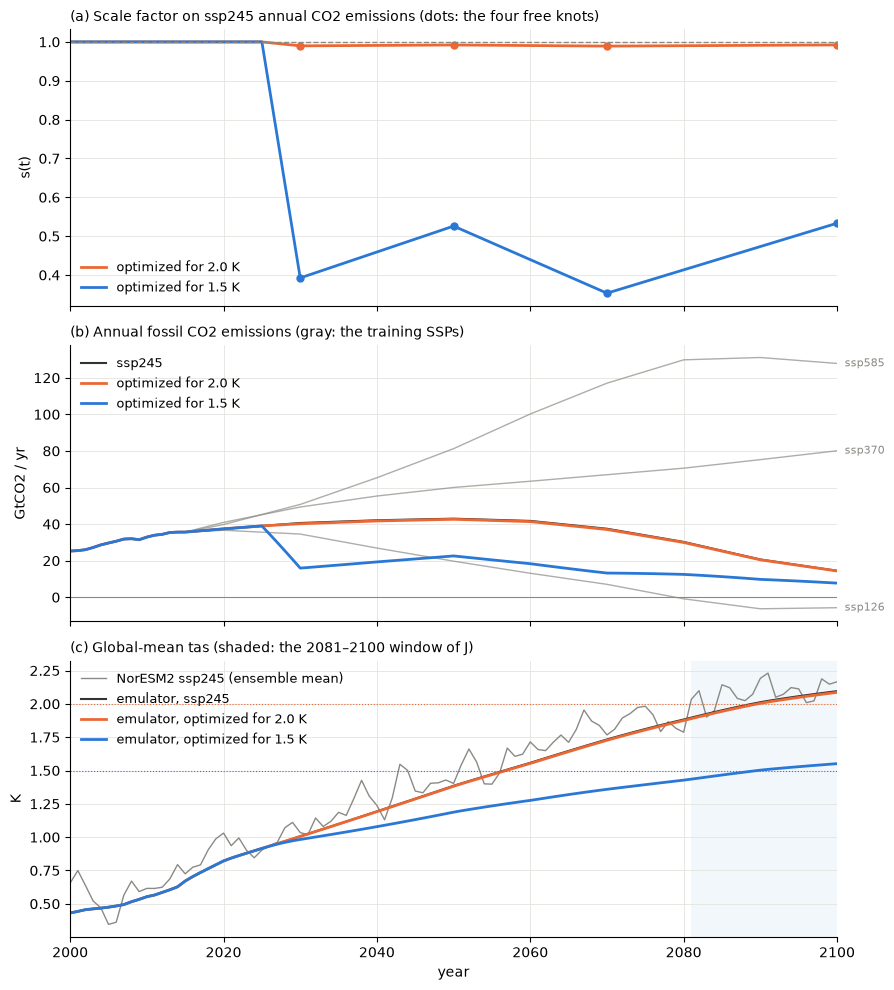

In [5]:
ssps = {exp: np.asarray(em.scenario_inputs(exp)[0]) for exp in ["ssp126", "ssp370", "ssp585"]}
fut = YEARS >= 2000
colors = {2.0: ORANGE, 1.5: BLUE}

fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)
ax = axes[0]
for target, r in runs.items():
    ax.plot(YEARS[fut], np.asarray(r["s"])[fut], color=colors[target], label=f"optimized for {target} K")
    ax.plot(KNOTS[1:], np.asarray(r["k"]), "o", color=colors[target], ms=5)
ax.axhline(1, color=GRAY, lw=1, ls="--")
ax.set_ylabel("s(t)")
ax.set_title("(a) Scale factor on ssp245 annual CO2 emissions (dots: the four free knots)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
for exp, c in ssps.items():
    ax.plot(YEARS[fut], np.diff(c, prepend=0.0)[fut], color=GRAY, lw=1, alpha=0.7)
    ax.text(2101, np.diff(c)[-1], exp, color=GRAY, fontsize=8, va="center")
ax.plot(YEARS[fut], np.asarray(E)[fut], color="#33332f", lw=1.5, label="ssp245")
for target, r in runs.items():
    ax.plot(YEARS[fut], np.asarray(r["s"] * E)[fut], color=colors[target], label=f"optimized for {target} K")
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_ylabel("GtCO2 / yr")
ax.set_title("(b) Annual fossil CO2 emissions (gray: the training SSPs)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9, loc="upper left")

ax = axes[2]
ax.axvspan(2081, 2100, color=BLUE, alpha=0.06, lw=0)
ax.plot(YEARS[fut], gmt(em.load_tas("historical").values).tolist()[150:] + gmt(em.load_tas("ssp245").values).tolist(),
        color=GRAY, lw=1, label="NorESM2 ssp245 (ensemble mean)")
ax.plot(YEARS[fut], np.asarray(gmt(emulate(co2, ch4, so2, bc)))[fut], color="#33332f", lw=1.5,
        label="emulator, ssp245")
for target, r in runs.items():
    ax.plot(YEARS[fut], np.asarray(gmt(emulate(r["co2"], ch4, so2, bc)))[fut], color=colors[target],
            label=f"emulator, optimized for {target} K")
    ax.axhline(target, color=colors[target], lw=0.8, ls=":")
ax.set_xlim(2000, 2100)
ax.set_xlabel("year")
ax.set_ylabel("K")
ax.set_title("(c) Global-mean tas (shaded: the 2081–2100 window of J)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(f"{FIGS}/week8_task4_pathway.png", dpi=150, bbox_inches="tight")

**The shape of the pathway.** The cheapest pathway does not cut the latest years hardest, and it does not cut the
largest emissions hardest. From Week 7 Task 2, a tonne emitted at any time before about 2080 has the same effect on $J$,
and $D$ charges the square of the tonnes removed in each year. The best answer is therefore to remove about the same
number of tonnes every year from 2026 to about 2080. In terms of $s$ that means $s - 1 \propto 1/E$: the factor stays
closest to 1 near 2050, where ssp245 emissions are largest, and the 2030 and 2070 knots move most. Emissions after
2080 count only partly in $J$, so the 2100 knot moves less than a cut of equal tonnes would need.

### How the pathway relates to the TCRE

The emulator's TCRE is 0.386 K per 1000 GtCO2 (Week 7 Task 2), and $J$ responds only to cumulative CO2. So the
reduction in $J$ should equal the TCRE times the reduction in cumulative CO2, averaged over the window with the 1-year
lag. Below, the cut in cumulative CO2 is compared with the cut that the TCRE predicts.

In [6]:
for target, r in runs.items():
    dJ = float(J(r["k"])) - J0
    cut = np.asarray(r["co2"] - co2)
    print(f"T* = {target} K: dJ = {dJ:+.3f} K. Cut in cumulative CO2: by 2080 {cut[2080 - 1850]:+.0f}, "
          f"by 2100 {cut[-1]:+.0f}, mean over 2081-2100 {cut[-20:].mean():+.0f} GtCO2. "
          f"dJ / TCRE = {1000 * dJ / TCRE:+.0f} GtCO2")
    print(f"           remaining budget from 2026: {float(r['co2'][-1] - co2[2025 - 1850]):.0f} GtCO2 to 2100 "
          f"(ssp245: {float(co2[-1] - co2[2025 - 1850]):.0f})")

T* = 2.0 K: dJ = -0.009 K. Cut in cumulative CO2: by 2080 -20, by 2100 -24, mean over 2081-2100 -22 GtCO2. dJ / TCRE = -22 GtCO2
           remaining budget from 2026: 2589 GtCO2 to 2100 (ssp245: 2613)
T* = 1.5 K: dJ = -0.508 K. Cut in cumulative CO2: by 2080 -1189, by 2100 -1414, mean over 2081-2100 -1325 GtCO2. dJ / TCRE = -1317 GtCO2
           remaining budget from 2026: 1199 GtCO2 to 2100 (ssp245: 2613)


The two numbers agree within a few percent. The small difference comes from the emissions inside the window: they
count in $J$ only for the years after they occur, so the mean cut over 2081–2100 is a little larger than the cut that
the TCRE gives. **The optimizer found the TCRE again.** In this emulator, a warming target is a budget of cumulative
CO2, and the only choice left to the optimizer is how to spread the cut over the years, which $D$ decides.

That is a property of the emulator, not a discovery. A real carbon budget has more terms: the zero-emissions
commitment, the CH4 and aerosol changes that come with a CO2 cut in real scenarios, and the curvature of the TCRE. The
emulator has none of these (see the Week 7 Task 2 and Task 3 notes).

### Is the optimized scenario inside the training range?

There are three ways to tell, from the simplest to the most direct:

1. **Each input, year by year.** Is the annual and the cumulative CO2 between the lowest and the highest training SSP
   in every year?
2. **The rate of change.** Is the fastest year-on-year fall in emissions faster than any training scenario has?
3. **The combination of inputs, as the emulator sees them.** The emulator uses four lagged, scaled features
   `[CO2, CH4, SO2 EOF1, BC EOF1]`. For each year we find the distance to the nearest year of any training experiment
   in that feature space. ssp245 is not in the training set, so its own distance is the reference: it is a scenario
   where we know the emulator works (Task 1 score).

In [7]:
feat = lambda c, m, s, b: np.asarray(em.features(params["const"], c, m, s, b))
train = np.concatenate([feat(*em.scenario_inputs(e))[-em.n_years(e):] for e in em.TRAIN])
train_exp = np.concatenate([[e] * em.n_years(e) for e in em.TRAIN])
ssp_years = YEARS >= 2015
yrs = YEARS[ssp_years]


def nearest(f):
    # distance (in scaled-feature units) from each row of f to the nearest training row, and that row's experiment
    d = np.sqrt(((f[:, None, :] - train[None, :, :]) ** 2).sum(-1))
    return d.min(1), train_exp[d.argmin(1)]


def fall(e):
    # fastest year-on-year fall in annual emissions from 2015, and its year
    step = -np.diff(e[ssp_years])
    return step.max(), yrs[1:][step.argmax()]


TRAIN_SSPS = ["ssp126", "ssp370", "ssp585"]
cum = np.stack([np.asarray(em.scenario_inputs(e)[0])[ssp_years] for e in TRAIN_SSPS])
ann = np.diff(np.stack([np.asarray(em.scenario_inputs(e)[0]) for e in TRAIN_SSPS]), prepend=0.0)[:, ssp_years]
print("fastest fall in annual CO2 (GtCO2/yr per year): "
      + ", ".join(f"{e} {fall(np.diff(np.asarray(em.scenario_inputs(e)[0]), prepend=0.0))[0]:.2f}" for e in TRAIN_SSPS)
      + f", ssp245 {fall(np.asarray(E))[0]:.2f} (in {fall(np.asarray(E))[1]})")


def years_out(x, low, high):
    # "below 2028-2078" style summary of the years where x leaves [low, high]
    parts = [f"{side} in {len(y)} years ({y.min()}-{y.max()})" for side, y in
             [("below", yrs[x < low - 1e-6]), ("above", yrs[x > high + 1e-6])] if len(y)]
    return ", ".join(parts) or "inside in every year"


dist = {"ssp245": nearest(feat(co2, ch4, so2, bc)[ssp_years])}
for target, r in runs.items():
    c, e = np.asarray(r["co2"])[ssp_years], np.asarray(r["s"] * E)[ssp_years]
    dist[f"optimized for {target} K"] = nearest(feat(r["co2"], ch4, so2, bc)[ssp_years])
    print(f"\nT* = {target} K, compared with the training SSPs:")
    print(f"  annual CO2:     {years_out(e, ann.min(0), ann.max(0))}")
    print(f"  cumulative CO2: {years_out(c, cum.min(0), cum.max(0))}; "
          f"2100 total {c[-1]:.0f} GtCO2 (ssp126 {cum[0, -1]:.0f})")
    print(f"  fastest fall {fall(np.asarray(r['s'] * E))[0]:.2f} GtCO2/yr per year (in "
          f"{fall(np.asarray(r['s'] * E))[1]}); lowest annual CO2 after 2025 {e[yrs > 2025].min():.1f} GtCO2/yr")
print()
for name, (d, exp) in dist.items():
    print(f"nearest-training distance, {name}: median {np.median(d):.2f}, max {d.max():.2f} "
          f"(in {yrs[d.argmax()]}); nearest experiment in 2100: {exp[-1]}")

fastest fall in annual CO2 (GtCO2/yr per year): ssp126 0.79, ssp370 -0.34, ssp585 0.33, ssp245 0.96 (in 2082)

T* = 2.0 K, compared with the training SSPs:
  annual CO2:     inside in every year
  cumulative CO2: inside in every year; 2100 total 4501 GtCO2 (ssp126 2793)
  fastest fall 0.95 GtCO2/yr per year (in 2090); lowest annual CO2 after 2025 14.4 GtCO2/yr

T* = 1.5 K, compared with the training SSPs:
  annual CO2:     below in 22 years (2026-2047)
  cumulative CO2: below in 51 years (2028-2078); 2100 total 3111 GtCO2 (ssp126 2793)
  fastest fall 4.77 GtCO2/yr per year (in 2030); lowest annual CO2 after 2025 7.7 GtCO2/yr

nearest-training distance, ssp245: median 0.65, max 1.03 (in 2100); nearest experiment in 2100: ssp126
nearest-training distance, optimized for 2.0 K: median 0.64, max 1.02 (in 2100); nearest experiment in 2100: ssp126
nearest-training distance, optimized for 1.5 K: median 0.34, max 0.53 (in 2100); nearest experiment in 2100: ssp126


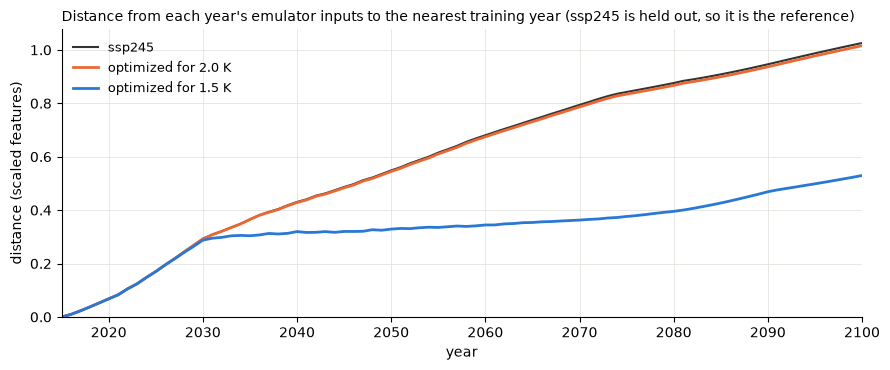

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for (name, (d, _)), color in zip(dist.items(), ["#33332f", ORANGE, BLUE]):
    ax.plot(YEARS[ssp_years], d, color=color, lw=1.5 if name == "ssp245" else 2, label=name)
ax.set_xlim(2015, 2100)
ax.set_ylim(0, None)
ax.set_xlabel("year")
ax.set_ylabel("distance (scaled features)")
ax.set_title("Distance from each year's emulator inputs to the nearest training year "
             "(ssp245 is held out, so it is the reference)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(f"{FIGS}/week8_task4_extrapolation.png", dpi=150, bbox_inches="tight")

## Notes (Task 4, and Question 3)

- **Setup.** $s(t)$ is linear between knots at 2030, 2050, 2070 and 2100, with $s = 1$ up to 2025. "As little change
  as possible" is the sum of squared changes in annual emissions after 2025, relative to ssp245's own ($D$). The penalty
  is $10^5 \cdot \mathrm{relu}(J - T^*)^2$. Optax L-BFGS gives the exact (Lagrange) answer to 3 decimals for both targets.
- **2 K.** ssp245 is already at 2.009 K in this emulator, so the answer is $s \approx 0.99$: a cut of about 24 GtCO2 by
  2100, less than one year of present emissions. It is inside the training range in every year.
- **1.5 K.** The knots are 0.39, 0.53, 0.35 and 0.53. Annual CO2 falls from 39 GtCO2/yr in 2025 to 16 in 2030, stays at
  13–23 until 2070, and is 7.7 in 2100. CO2 emitted from 2026 to 2100 is 1199 GtCO2 (ssp245: 2613).
- **TCRE.** The cut in $J$ divided by the TCRE (0.386) is 1317 GtCO2, and the mean cut in cumulative CO2 over the window
  is 1325 GtCO2. In this emulator a warming target is a cumulative-CO2 budget, so the optimizer only decides how to
  spread the cut. $D$ makes it remove about the same tonnes every year until about 2080, so $s$ stays nearest to 1
  near 2050, where emissions are largest.
- **Optimizer.** Adam does not find the answer. The penalty makes a steep wall, and $D$ is almost flat along it. With a
  constant step Adam misses the target (1.473 K). With a decaying step it reaches 1.500 K but keeps four almost equal
  knots ($D$ 0.3011 against 0.2991). L-BFGS uses curvature and finds the minimum in fewer than 100 steps.
- **Inside the training range?** It depends on the test:
  - Each input against the training SSPs: no. Annual CO2 is below ssp126 in 2026–2047, and cumulative CO2 is below it
    in 2028–2078. The 2025–2030 cut is 4.8 GtCO2/yr per year, 6 times the fastest fall in any training SSP (ssp126, 0.79).
  - The emulator's own features (lagged CO2, CH4, SO2 EOF1, BC EOF1): yes. Every year is nearer to a training year
    (median distance 0.34, nearest experiment ssp126) than ssp245 is (0.65). So the emulator interpolates here.
  - The two tests disagree because the features cannot see the rate of a cut. With a 1-year lag on cumulative CO2,
    the emulator gives the same answer for a fast and a slow cut to the same total. A feature-space test is blind to
    anything that the emulator does not use. So it can show that the emulator is not outside its own data, but it
    cannot show that NorESM2 would agree.
- **Would we trust it for policy? No.** The largest problem is the CO2 coefficient. The emulator's TCRE (0.386) is
  1.37 times NorESM2's CO2-only TCRE from 1pctCO2 (0.28, Week 7), because the coefficient also takes the warming of N2O
  and halocarbons, which rise with CO2 in the SSPs. The optimizer cuts only CO2, so those gases stay as in ssp245.
  With 0.28 the same cut gives 0.37 K, not 0.51 K, so the 1.5 K pathway would give about 1.64 K. The emulator also
  has no zero-emissions commitment and no slow climate response (1-year lag), and the 4.8 GtCO2/yr-per-year cut is
  far outside anything NorESM2 was run with.
- **What would make us trust it more:** run the optimized pathway in a model with a physical carbon cycle (FaIR, or
  NorESM2 itself); give the emulator separate terms for CO2 and the other greenhouse gases, and a slow response (a
  FaIR-like core); report a range from several emulators or seeds (Task 6); and the Task 5 stress tests.